# Fase 1 y 2 CRISP-DM: Comprensión del Negocio y Análisis Exploratorio de Datos (EDA)
**Proyecto Final — Algoritmos y Programación III (Semestre 2026-2)**  
**Universidad Icesi — Departamento de Computación y Sistemas Inteligentes**

---

## 1. Comprensión del Negocio y Formulación Matemática (Indicadores PI1, PI2 y PI3)

### 1.1. Contexto del Problema
En mercados minoristas, plazas de mercado y líneas agroindustriales, la inspección visual manual de frutas frescas según su **calidad superficial** (madurez, manchas fúngicas, magulladuras, podredumbre) y su **tamaño (calibre)** es un proceso lento, subjetivo y propenso a errores por fatiga. Esto genera mermas económicas y desperdicio alimentario.

### 1.2. Formulación Matemática del Problema (PI3)
Sea una imagen digital estática en espacio RGB representada como un tensor discreto:
$$I \in [0, 255]^{H \times W \times 3}$$
donde $H$ es la altura en píxeles, $W$ es el ancho en píxeles y los 3 canales corresponden a $(R, G, B)$.

El sistema debe aprender dos funciones de mapeo sobre $I$:
1. **Clasificación de Calidad ($f_{\theta}$):** Asigna una de las **3 categorías de calidad** definidas para el proyecto:
   $$\hat{y}_{\text{qual}} = f_{\theta}(\phi(I)) \in \{\text{Good (Buena)},\; \text{Mixed/Medium (Regular)},\; \text{Bad (Mala)}\}$$
2. **Estimación Morfométrica de Tamaño Relativo ($g$):** Mediante segmentación del primer plano se obtiene la máscara binaria de la fruta $M \in \{0, 1\}^{H \times W}$, donde $M(u, v) = 1$ indica que el píxel $(u,v)$ pertenece a la fruta. El área ocupada es $A_{\text{fruta}} = \sum_{u=1}^{H}\sum_{v=1}^{W} M(u,v)$, y el **diámetro equivalente en píxeles normalizados** se define como:
   $$d_{\text{norm}}(I) = \sqrt{\frac{4 \cdot A_{\text{fruta}}}{\pi \cdot (H \cdot W)}} \in [0, 1]$$
   A partir de los terciles empíricos $(q_{1/3}, q_{2/3})$ de $d_{\text{norm}}$ por tipo de fruta, se clasifica el calibre en:
   $$\hat{y}_{\text{size}} \in \{\text{Small (Pequeño)},\; \text{Medium (Mediano)},\; \text{Large (Grande)}\}$$

In [1]:
# 1. Importación de librerías para el Análisis Exploratorio de Datos (EDA)
from pathlib import Path
import math
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from scipy import ndimage

# Configuración visual de las gráficas en el cuaderno
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 10,
    'axes.titlesize': 12,
    'axes.titleweight': 'bold',
    'axes.labelsize': 10,
    'figure.dpi': 120
})
QUALITY_PALETTE = {'Good': '#2ca02c', 'Mixed': '#ff7f0e', 'Bad': '#d62728'}

# Localizar la raíz del proyecto y las carpetas del dataset de Kaggle
REPO_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
WORKSPACE_ROOT = REPO_ROOT.parent
RESULTS_DIR = REPO_ROOT / 'experiments' / 'results'
FIGURES_DIR = RESULTS_DIR / 'eda_figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f'Directorio del Dataset : {WORKSPACE_ROOT}')
print(f'Directorio del Repo    : {REPO_ROOT}')

Directorio del Dataset : C:\Users\gigi\Desktop\7_Semestre\APO_3\Proyecto_Final_APO3
Directorio del Repo    : C:\Users\gigi\Desktop\7_Semestre\APO_3\Proyecto_Final_APO3\Project_Fruit_Classification


---
## 2. Indexación e Inventario del Dataset (Fase 2: Comprensión de los Datos)

Recorremos las tres carpetas principales del dataset *Fruit Quality Classification* de Kaggle:
- `Good Quality_Fruits` (Calidad **Buena**)
- `Bad Quality_Fruits` (Calidad **Mala**)
- `Mixed Qualit_Fruits` (Calidad **Mixta / Intermedia**)

> **Nota de limpieza durante la indexación:** En `Good` y `Bad` la carpeta de limón se denomina `Lime_Good` / `Lime_Bad`, mientras que en `Mixed Qualit_Fruits` se denomina `Lemon`. Las unificamos bajo la etiqueta canónica `Lime`.

In [2]:
CANONICAL_FRUIT_MAP = {
    'apple': 'Apple',
    'banana': 'Banana',
    'guava': 'Guava',
    'lime': 'Lime',
    'lemon': 'Lime',
    'orange': 'Orange',
    'pomegranate': 'Pomegranate',
}

QUALITY_FOLDERS = {
    'Good Quality_Fruits': 'Good',
    'Bad Quality_Fruits': 'Bad',
    'Mixed Qualit_Fruits': 'Mixed',
}

VALID_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

records = []
for folder_name, quality_label in QUALITY_FOLDERS.items():
    folder_path = WORKSPACE_ROOT / folder_name
    if not folder_path.exists():
        continue
    for subfolder in sorted(folder_path.iterdir()):
        if not subfolder.is_dir():
            continue
        raw_fruit = subfolder.name.split('_')[0].strip().lower()
        fruit_name = CANONICAL_FRUIT_MAP.get(raw_fruit, subfolder.name)
        for img_path in sorted(subfolder.iterdir()):
            if img_path.is_file() and img_path.suffix.lower() in VALID_EXTENSIONS:
                records.append({
                    'filepath': str(img_path),
                    'filename': img_path.name,
                    'source_folder': folder_name,
                    'subfolder': subfolder.name,
                    'fruit': fruit_name,
                    'quality': quality_label,
                    'class_combined': f'{fruit_name}_{quality_label}',
                    'file_size_kb': round(img_path.stat().st_size / 1024.0, 2)
                })

df_inv = pd.DataFrame(records)
df_inv.to_csv(RESULTS_DIR / 'dataset_inventory.csv', index=False)
print(f'Total de imágenes indexadas: {len(df_inv):,}')
df_inv.head()

Total de imágenes indexadas: 19,526


,filepath,filename,source_folder,subfolder,fruit,quality,class_combined,file_size_kb
0,C:\Users\gigi\Desktop\7_Semestre\APO_3\Proyect...,20190809_115439.jpg,Good Quality_Fruits,Apple_Good,Apple,Good,Apple_Good,19.75
1,C:\Users\gigi\Desktop\7_Semestre\APO_3\Proyect...,20190809_115448.jpg,Good Quality_Fruits,Apple_Good,Apple,Good,Apple_Good,9.40
2,C:\Users\gigi\Desktop\7_Semestre\APO_3\Proyect...,20190809_115451.jpg,Good Quality_Fruits,Apple_Good,Apple,Good,Apple_Good,18.19
3,C:\Users\gigi\Desktop\7_Semestre\APO_3\Proyect...,20190809_115459.jpg,Good Quality_Fruits,Apple_Good,Apple,Good,Apple_Good,19.13
4,C:\Users\gigi\Desktop\7_Semestre\APO_3\Proyect...,20190809_115505.jpg,Good Quality_Fruits,Apple_Good,Apple,Good,Apple_Good,21.65


### 2.1. Tabla Resumen por Fruta, Calidad y Tamaño de Archivo (KB)
Analizamos la cantidad de imágenes por subclase y el peso en kilobytes para detectar anomalías de resolución o compresión.

In [3]:
summary_table = (
    df_inv.groupby(['fruit', 'quality'])
    .agg(
        image_count=('filepath', 'count'),
        mean_kb=('file_size_kb', 'mean'),
        min_kb=('file_size_kb', 'min'),
        max_kb=('file_size_kb', 'max')
    )
    .reset_index()
)
summary_table['mean_kb'] = summary_table['mean_kb'].round(2)
summary_table.to_csv(RESULTS_DIR / 'eda_class_summary.csv', index=False)

# Mostrar tabla pivoteada de conteos y resumen estadístico de archivos
pivot_counts = df_inv.pivot_table(index='fruit', columns='quality', values='filepath', aggfunc='count', fill_value=0)[['Good', 'Bad', 'Mixed']]
pivot_counts['Total_Fruta'] = pivot_counts.sum(axis=1)
display(pivot_counts)
display(summary_table)

quality,Good,Bad,Mixed,Total_Fruta
fruit,,,,
Apple,1149,1141,113,2403
Banana,1113,1087,285,2485
Guava,1152,1129,148,2429
Lime,1094,1085,278,2457
Orange,1216,1159,125,2500
Pomegranate,5940,1187,125,7252


,fruit,quality,image_count,mean_kb,min_kb,max_kb
0,Apple,Bad,1141,18.60,4.66,28.95
1,Apple,Good,1149,15.59,4.74,61.01
2,Apple,Mixed,113,18.99,15.11,22.16
3,Banana,Bad,1087,23.25,5.87,36.06
4,Banana,Good,1113,27.15,6.44,32.62
5,Banana,Mixed,285,13.61,5.76,24.41
6,Guava,Bad,1129,20.13,5.07,27.59
7,Guava,Good,1152,17.81,4.64,33.72
8,Guava,Mixed,148,10.65,5.84,20.96
9,Lime,Bad,1085,18.22,5.31,28.04


### 2.2. Cuantificación Matemática del Desbalance de Clases
Calculamos dos indicadores formales:
1. **Razón de Desbalance (*Imbalance Ratio*, $IR$):**
   $$IR = \frac{\max_{c} N_c}{\min_{c} N_c}$$
2. **Entropía de Shannon Normalizada ($H_{\text{norm}} \in [0, 1]$):** Mide qué tan uniforme es la distribución de probabilidad empírica $p_c = N_c / N$ frente a una distribución perfectamente balanceada ($H_{\text{norm}} = 1$):
   $$H_{\text{norm}} = -\frac{1}{\ln K} \sum_{c=1}^{K} p_c \ln(p_c)$$

In [4]:
class_counts = df_inv['class_combined'].value_counts()
gb_counts = df_inv[df_inv['quality'].isin(['Good', 'Bad'])]['class_combined'].value_counts()

ir_all = class_counts.max() / class_counts.min()
ir_gb = gb_counts.max() / gb_counts.min()

probs = class_counts / class_counts.sum()
shannon_h = -(probs * np.log(probs)).sum()
shannon_norm = shannon_h / math.log(len(class_counts))

print(f'Imbalance Ratio (12 clases Good/Bad) : {ir_gb:.2f}x  (Pomegranate_Good={gb_counts.max()} vs Lime_Bad={gb_counts.min()})')
print(f'Imbalance Ratio (18 subclases total) : {ir_all:.2f}x  (Pomegranate_Good={class_counts.max()} vs Apple_Mixed={class_counts.min()})')
print(f'Entropía de Shannon (H)              : {shannon_h:.4f} nats')
print(f'Eficiencia de Balance (H_norm)       : {shannon_norm:.4f} (1.0 = perfectamente balanceado)')

Imbalance Ratio (12 clases Good/Bad) : 5.47x  (Pomegranate_Good=5940 vs Lime_Bad=1085)
Imbalance Ratio (18 subclases total) : 52.57x  (Pomegranate_Good=5940 vs Apple_Mixed=113)
Entropía de Shannon (H)              : 2.4371 nats
Eficiencia de Balance (H_norm)       : 0.8432 (1.0 = perfectamente balanceado)


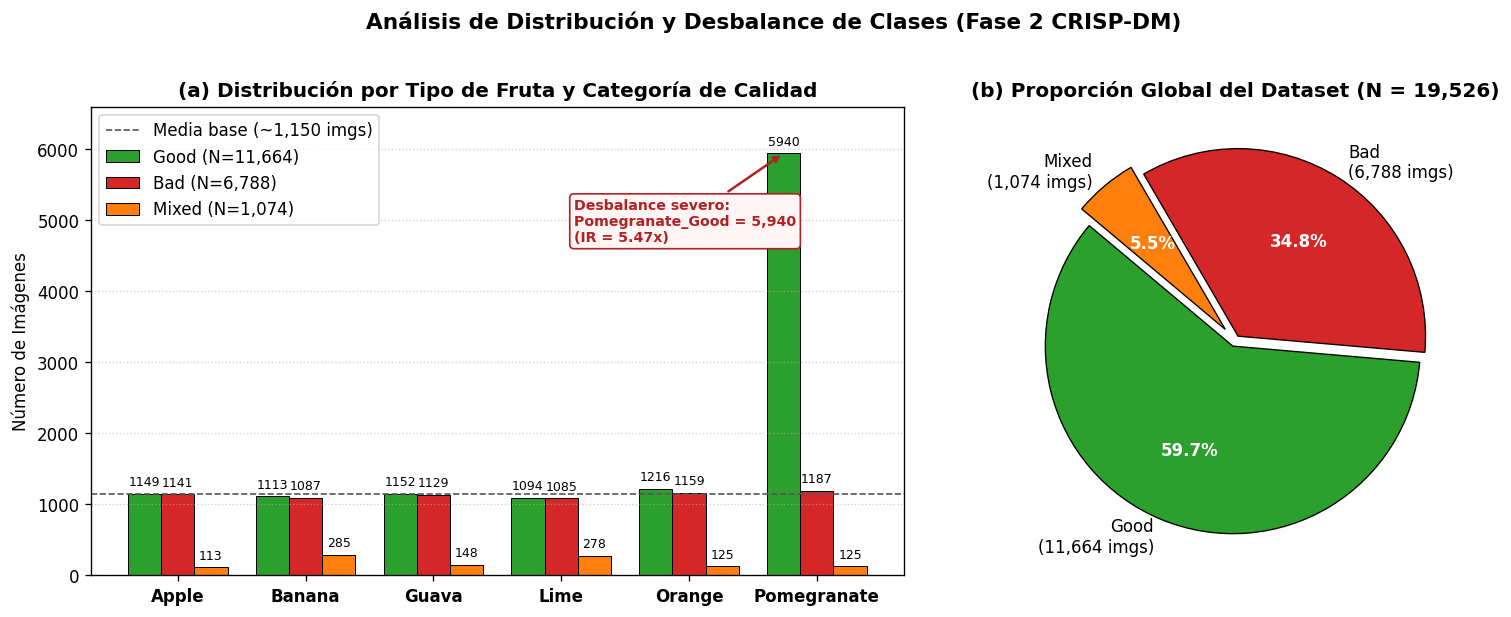

In [5]:
# Gráfica 1: Distribución de clases y proporción global
pivot = df_inv.pivot_table(index='fruit', columns='quality', values='filepath', aggfunc='count', fill_value=0)[['Good', 'Bad', 'Mixed']]

fig, axes = plt.subplots(1, 2, figsize=(13, 5.0), gridspec_kw={'width_ratios': [1.35, 1.0]})

x = np.arange(len(pivot.index))
width = 0.26
for i, qual in enumerate(['Good', 'Bad', 'Mixed']):
    vals = pivot[qual].values
    bars = axes[0].bar(x + (i - 1) * width, vals, width=width, label=f'{qual} (N={vals.sum():,})',
                       color=QUALITY_PALETTE[qual], edgecolor='black', linewidth=0.6)
    for b in bars:
        h = b.get_height()
        axes[0].text(b.get_x() + b.get_width()/2.0, h + 80, f'{int(h)}', ha='center', va='bottom', fontsize=7.5)

axes[0].set_xticks(x)
axes[0].set_xticklabels(pivot.index, fontweight='bold')
axes[0].set_ylabel('Número de Imágenes')
axes[0].set_ylim(0, 6600)
axes[0].set_title('(a) Distribución por Tipo de Fruta y Categoría de Calidad')
axes[0].axhline(1150, color='#555555', linestyle='--', linewidth=1.0, label='Media base (~1,150 imgs)')
axes[0].annotate('Desbalance severo:\nPomegranate_Good = 5,940\n(IR = 5.47x)',
                 xy=(5 - width, 5940), xytext=(3.1, 4700),
                 arrowprops=dict(arrowstyle='->', color='#b22222', lw=1.5),
                 fontsize=8.5, fontweight='bold', color='#b22222',
                 bbox=dict(boxstyle='round,pad=0.3', fc='#fff5f5', ec='#b22222'))
axes[0].legend(loc='upper left', frameon=True)
axes[0].grid(axis='y', linestyle=':', alpha=0.6)

qual_counts = df_inv['quality'].value_counts().reindex(['Good', 'Bad', 'Mixed'])
wedges, texts, autotexts = axes[1].pie(
    qual_counts.values,
    labels=[f'{k}\n({v:,} imgs)' for k, v in qual_counts.items()],
    autopct='%1.1f%%', startangle=140,
    colors=[QUALITY_PALETTE[k] for k in qual_counts.index],
    explode=(0.03, 0.03, 0.08),
    wedgeprops=dict(edgecolor='black', linewidth=0.8)
)
for at in autotexts:
    at.set_color('white')
    at.set_fontweight('bold')
axes[1].set_title('(b) Proporción Global del Dataset (N = 19,526)')

fig.suptitle('Análisis de Distribución y Desbalance de Clases (Fase 2 CRISP-DM)', fontsize=13, fontweight='bold', y=1.02)
fig.tight_layout()
fig.savefig(FIGURES_DIR / '01_class_distribution_imbalance.pdf', bbox_inches='tight')
fig.savefig(FIGURES_DIR / '01_class_distribution_imbalance.png', dpi=200, bbox_inches='tight')
plt.show()

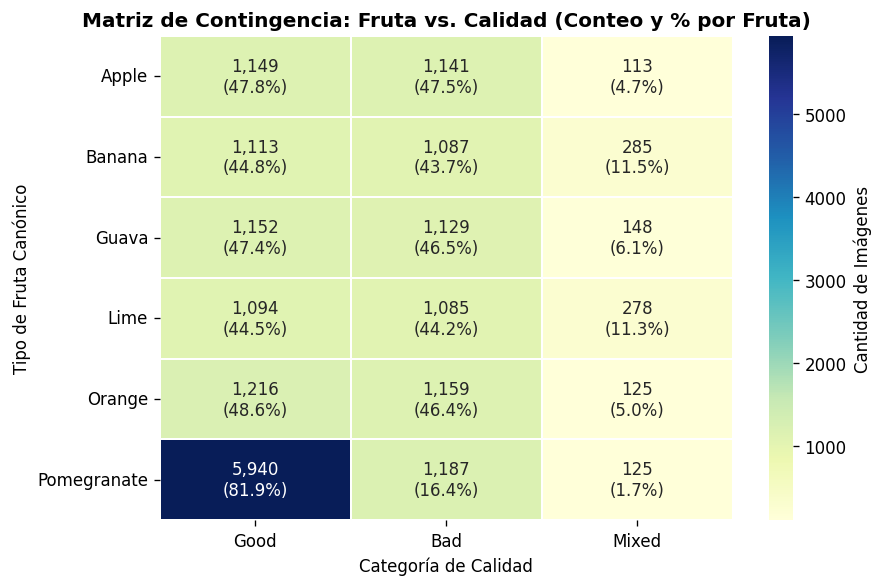

In [6]:
# Gráfica 2: Mapa de calor de contingencia Fruta vs. Calidad
row_pct = pivot.div(pivot.sum(axis=1), axis=0) * 100.0
annot_matrix = np.empty(pivot.shape, dtype=object)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        annot_matrix[i, j] = f'{pivot.iloc[i, j]:,}\n({row_pct.iloc[i, j]:.1f}%)'

fig, ax = plt.subplots(figsize=(7.5, 5.0))
sns.heatmap(pivot, annot=annot_matrix, fmt='', cmap='YlGnBu',
            cbar_kws={'label': 'Cantidad de Imágenes'}, linewidths=1.0, linecolor='white', ax=ax)
ax.set_title('Matriz de Contingencia: Fruta vs. Calidad (Conteo y % por Fruta)')
ax.set_xlabel('Categoría de Calidad')
ax.set_ylabel('Tipo de Fruta Canónico')
fig.tight_layout()
fig.savefig(FIGURES_DIR / '02_contingency_heatmap.pdf', bbox_inches='tight')
fig.savefig(FIGURES_DIR / '02_contingency_heatmap.png', dpi=200, bbox_inches='tight')
plt.show()

---
## 3. Exploración Visual del Dataset (Mosaico de Ejemplares)
Visualizamos una muestra de cada fruta en sus 3 carpetas (`Good`, `Bad`, `Mixed`) para inspeccionar fondos, iluminación, artefactos (como manos con guantes) y la presencia de múltiples frutas por imagen en `Mixed Qualit_Fruits`.

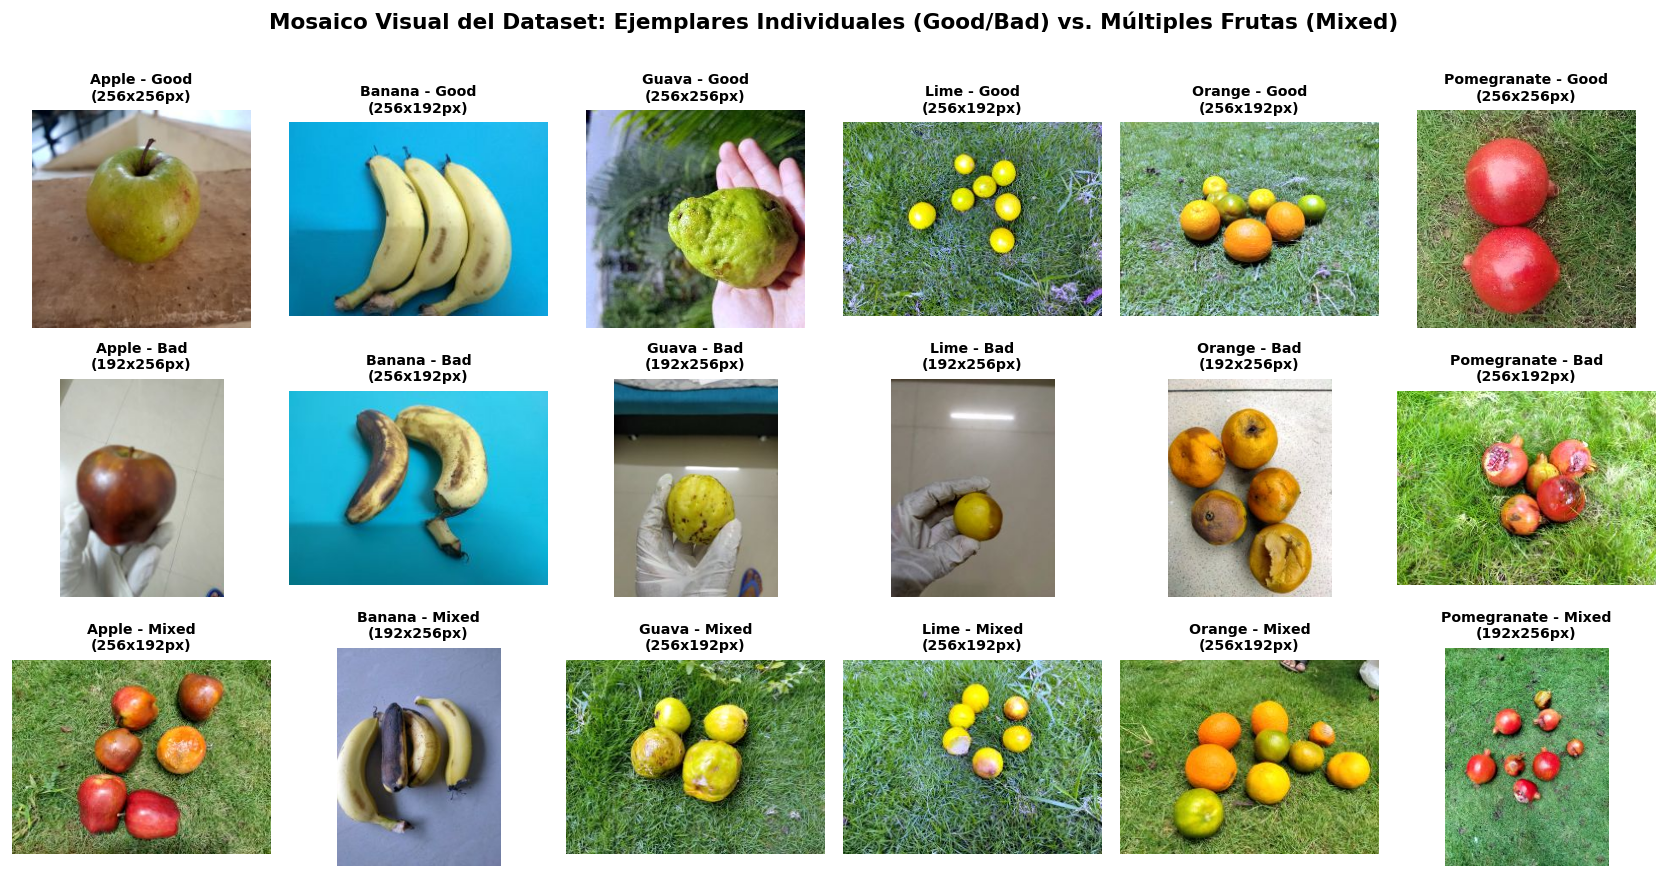

In [7]:
fruits = ['Apple', 'Banana', 'Guava', 'Lime', 'Orange', 'Pomegranate']
qualities = ['Good', 'Bad', 'Mixed']

fig, axes = plt.subplots(len(qualities), len(fruits), figsize=(14, 7.2))
for r_idx, qual in enumerate(qualities):
    for c_idx, fruit in enumerate(fruits):
        ax = axes[r_idx, c_idx]
        sub = df_inv[(df_inv['fruit'] == fruit) & (df_inv['quality'] == qual)]
        if len(sub) > 0:
            img_path = sub.iloc[0]['filepath']
            with Image.open(img_path) as img:
                w, h = img.size
                ax.imshow(img.convert('RGB'))
            ax.set_title(f'{fruit} - {qual}\n({w}x{h}px)', fontsize=8.5)
        ax.axis('off')

fig.suptitle('Mosaico Visual del Dataset: Ejemplares Individuales (Good/Bad) vs. Múltiples Frutas (Mixed)',
             fontsize=13, fontweight='bold', y=1.01)
fig.tight_layout()
fig.savefig(FIGURES_DIR / '06_visual_mosaic_samples.pdf', bbox_inches='tight')
fig.savefig(FIGURES_DIR / '06_visual_mosaic_samples.png', dpi=200, bbox_inches='tight')
plt.show()

---
## 4. Segmentación Morfológica, Estimación de Tamaño ($d_{\text{norm}}$) y Características de Color/Textura

Para cumplir con el requerimiento de **estimación de tamaño relativo** (`Small`, `Medium`, `Large`) y analizar la separabilidad de las clases para los modelos de Machine Learning tradicional, definimos directamente en el cuaderno el algoritmo matemático de segmentación:

1. **Conversión RGB $\rightarrow$ HSV** y estimación del color mediano del borde perimetral $\mathbf{b}_{\text{bg}} \in \mathbb{R}^3$.
2. **Mapa de Saliencia Cromática:** Combinación convexa de la distancia euclidiana respecto al fondo y la saturación $S$:
   $$S_{\text{map}}(u,v) = 0.70 \cdot \frac{\|I(u,v) - \mathbf{b}_{\text{bg}}\|_2}{\sqrt{3}} + 0.30 \cdot S(u,v)$$
3. **Umbralización Óptima de Otsu:** Selección del umbral $t^*$ que maximiza la varianza inter-clase $\sigma_B^2(t) = \omega_0(t)\omega_1(t)[\mu_0(t) - \mu_1(t)]^2$, seguida de cierre morfológico y selección de la componente conexa principal.
4. **Cálculo del Diámetro Equivalente Normalizado:**
   $$d_{\text{norm}} = \sqrt{\frac{4 \cdot A_{\text{fruta}}}{\pi \cdot H \cdot W}}$$

In [8]:
def otsu_threshold(gray_values: np.ndarray) -> float:
    """Calcula el umbral óptimo de Otsu maximizando la varianza inter-clase."""
    hist, bin_edges = np.histogram(gray_values.ravel(), bins=256, range=(0.0, 1.0))
    hist = hist.astype(np.float64)
    total = hist.sum()
    if total == 0:
        return 0.5
    prob = hist / total
    bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
    w0 = np.cumsum(prob)
    w1 = 1.0 - w0
    mu = np.cumsum(prob * bin_centers)
    mu_total = mu[-1]
    valid = (w0 > 1e-6) & (w1 > 1e-6)
    sigma_b_sq = np.zeros_like(w0)
    sigma_b_sq[valid] = ((mu_total * w0[valid] - mu[valid]) ** 2) / (w0[valid] * w1[valid])
    return float(bin_centers[int(np.argmax(sigma_b_sq))])


def rgb_to_hsv_array(rgb_norm: np.ndarray) -> np.ndarray:
    """Convierte imagen RGB en [0, 1] al espacio HSV en [0, 1]."""
    r, g, b = rgb_norm[..., 0], rgb_norm[..., 1], rgb_norm[..., 2]
    maxc = np.maximum(np.maximum(r, g), b)
    minc = np.minimum(np.minimum(r, g), b)
    v = maxc
    deltac = maxc - minc
    s = np.where(maxc > 1e-6, deltac / np.maximum(maxc, 1e-6), 0.0)
    h = np.zeros_like(maxc)
    mask = deltac > 1e-6
    rc = np.where(mask, (maxc - r) / np.maximum(deltac, 1e-6), 0.0)
    gc = np.where(mask, (maxc - g) / np.maximum(deltac, 1e-6), 0.0)
    bc = np.where(mask, (maxc - b) / np.maximum(deltac, 1e-6), 0.0)
    cond_r = mask & (r == maxc)
    cond_g = mask & (g == maxc) & ~cond_r
    cond_b = mask & ~cond_r & ~cond_g
    h[cond_r] = bc[cond_r] - gc[cond_r]
    h[cond_g] = 2.0 + rc[cond_g] - bc[cond_g]
    h[cond_b] = 4.0 + gc[cond_b] - rc[cond_b]
    h = (h / 6.0) % 1.0
    return np.stack([h, s, v], axis=-1)


def segment_fruit_foreground(rgb_norm: np.ndarray) -> np.ndarray:
    """Segmenta la fruta del fondo y retorna la máscara booleana M(u,v)."""
    h, w, _ = rgb_norm.shape
    hsv = rgb_to_hsv_array(rgb_norm)
    border_px = max(2, min(h, w) // 25)
    border_samples = np.concatenate([
        rgb_norm[:border_px, :, :].reshape(-1, 3),
        rgb_norm[-border_px:, :, :].reshape(-1, 3),
        rgb_norm[:, :border_px, :].reshape(-1, 3),
        rgb_norm[:, -border_px:, :].reshape(-1, 3)
    ], axis=0)
    bg_rgb = np.median(border_samples, axis=0)
    color_dist = np.linalg.norm(rgb_norm - bg_rgb[None, None, :], axis=-1) / math.sqrt(3.0)
    salience = np.clip(0.70 * color_dist + 0.30 * hsv[..., 1], 0.0, 1.0)
    thresh = otsu_threshold(salience)
    mask = salience > max(thresh, 0.12)
    mask = ndimage.binary_closing(mask, structure=np.ones((5, 5)))
    mask = ndimage.binary_fill_holes(mask)
    labeled, num_features = ndimage.label(mask)
    if num_features > 1:
        sizes = ndimage.sum(mask, labeled, range(1, num_features + 1))
        mask = labeled == (int(np.argmax(sizes)) + 1)
    if mask.sum() < 0.02 * (h * w):
        yy, xx = np.ogrid[:h, :w]
        mask = ((yy - h/2.0)**2 + (xx - w/2.0)**2) <= (min(h, w)*0.35)**2
    return mask


def extract_image_features(image_path: str) -> dict:
    """Extrae tamaño relativo (d_norm, area_ratio) y descriptores de color/textura."""
    with Image.open(image_path) as img:
        img_rgb = img.convert('RGB')
        width, height = img_rgb.size
        rgb_arr = np.asarray(img_rgb, dtype=np.float32) / 255.0
    mask = segment_fruit_foreground(rgb_arr)
    hsv_arr = rgb_to_hsv_array(rgb_arr)
    total_pixels = float(height * width)
    fruit_area_px = float(mask.sum())
    area_ratio = fruit_area_px / total_pixels
    d_norm = math.sqrt((4.0 * fruit_area_px) / (math.pi * total_pixels))
    fg_rgb = rgb_arr[mask]
    fg_hsv = hsv_arr[mask]
    gray = 0.299 * rgb_arr[..., 0] + 0.587 * rgb_arr[..., 1] + 0.114 * rgb_arr[..., 2]
    laplacian_var = float(np.var(ndimage.laplace(gray)[mask]))
    return {
        'width': width, 'height': height,
        'area_ratio': round(area_ratio, 4),
        'd_norm': round(d_norm, 4),
        'mean_R': round(float(fg_rgb[:, 0].mean()), 4),
        'mean_G': round(float(fg_rgb[:, 1].mean()), 4),
        'mean_B': round(float(fg_rgb[:, 2].mean()), 4),
        'mean_H': round(float(fg_hsv[:, 0].mean()), 4),
        'mean_S': round(float(fg_hsv[:, 1].mean()), 4),
        'mean_V': round(float(fg_hsv[:, 2].mean()), 4),
        'std_S': round(float(fg_hsv[:, 1].std()), 4),
        'std_V': round(float(fg_hsv[:, 2].std()), 4),
        'laplacian_var': round(laplacian_var, 6)
    }

In [9]:
# Extraer características sobre una muestra estratificada (40 imágenes por cada una de las 18 subclases = 720 imágenes)
sampled_groups = [
    grp.sample(n=min(len(grp), 40), random_state=42)
    for _, grp in df_inv.groupby('class_combined')
]
df_sample = pd.concat(sampled_groups, ignore_index=True)

feature_rows = []
for row in df_sample.itertuples(index=False):
    feats = extract_image_features(row.filepath)
    feature_rows.append({**row._asdict(), **feats})

df_feats = pd.DataFrame(feature_rows)

# Asignar categoría de tamaño (Small, Medium, Large) según terciles de d_norm por tipo de fruta
def categorize_size(series: pd.Series) -> pd.Series:
    q1, q2 = series.quantile(1/3), series.quantile(2/3)
    return pd.Series(np.where(series < q1, 'Small', np.where(series < q2, 'Medium', 'Large')), index=series.index)

df_feats['size_category'] = df_feats.groupby('fruit', group_keys=False)['d_norm'].apply(categorize_size)
df_feats.to_csv(RESULTS_DIR / 'eda_sampled_features.csv', index=False)

# Tabla de umbrales de tamaño por fruta
df_size_summary = (
    df_feats[df_feats['quality'].isin(['Good', 'Bad'])]
    .groupby(['fruit', 'size_category'])
    .agg(count=('d_norm', 'count'), mean_d_norm=('d_norm', 'mean'), min_d_norm=('d_norm', 'min'), max_d_norm=('d_norm', 'max'), mean_area=('area_ratio', 'mean'))
    .reset_index().round(4)
)
df_size_summary.to_csv(RESULTS_DIR / 'eda_size_thresholds.csv', index=False)
display(df_size_summary)

,fruit,size_category,count,mean_d_norm,min_d_norm,max_d_norm,mean_area
0,Apple,Large,9,0.8475,0.8069,0.9005,0.5651
1,Apple,Medium,31,0.6937,0.6345,0.8018,0.3797
2,Apple,Small,40,0.4832,0.2754,0.6336,0.1902
3,Banana,Large,18,0.8657,0.7291,1.0943,0.5967
4,Banana,Medium,31,0.6552,0.5755,0.7256,0.3383
5,Banana,Small,31,0.4900,0.2731,0.5744,0.1917
6,Guava,Large,24,0.8294,0.7080,1.1074,0.5516
7,Guava,Medium,38,0.6341,0.5212,0.7017,0.3178
8,Guava,Small,18,0.3958,0.1929,0.5142,0.1299
9,Lime,Large,31,0.6942,0.6411,0.8735,0.3808


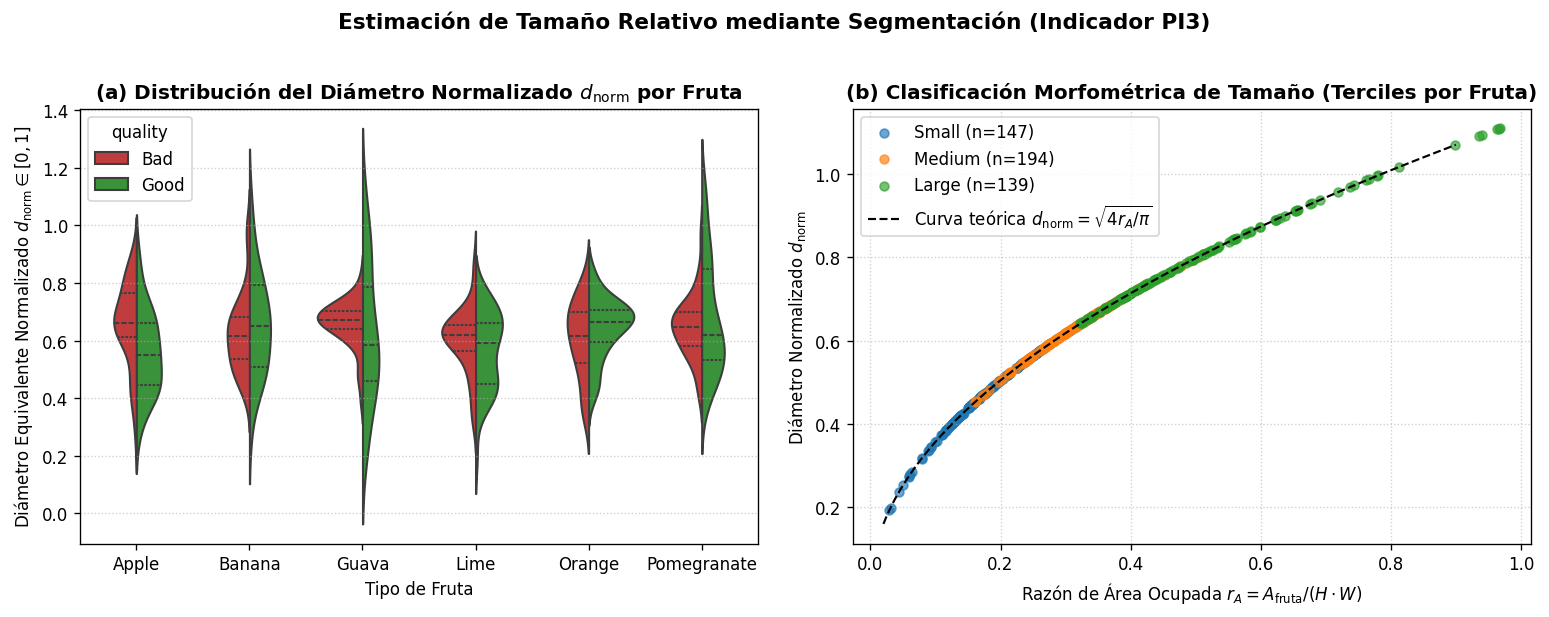

In [10]:
# Gráfica 3: Distribución de Diámetro Normalizado (d_norm) y Clasificación de Tamaño
df_indiv = df_feats[df_feats['quality'].isin(['Good', 'Bad'])].copy()

fig, axes = plt.subplots(1, 2, figsize=(13, 5.0))
sns.violinplot(data=df_indiv, x='fruit', y='d_norm', hue='quality', split=True, inner='quart',
               palette={'Good': QUALITY_PALETTE['Good'], 'Bad': QUALITY_PALETTE['Bad']}, ax=axes[0])
axes[0].set_title(r'(a) Distribución del Diámetro Normalizado $d_{\mathrm{norm}}$ por Fruta')
axes[0].set_xlabel('Tipo de Fruta')
axes[0].set_ylabel(r'Diámetro Equivalente Normalizado $d_{\mathrm{norm}} \in [0, 1]$')
axes[0].grid(axis='y', linestyle=':', alpha=0.6)

size_palette = {'Small': '#1f77b4', 'Medium': '#ff7f0e', 'Large': '#2ca02c'}
for sz in ['Small', 'Medium', 'Large']:
    sub = df_indiv[df_indiv['size_category'] == sz]
    axes[1].scatter(sub['area_ratio'], sub['d_norm'], label=f'{sz} (n={len(sub)})',
                    color=size_palette[sz], alpha=0.65, s=28)

r_grid = np.linspace(0.02, 0.90, 200)
axes[1].plot(r_grid, np.sqrt((4.0 * r_grid) / math.pi), 'k--', lw=1.3, label=r'Curva teórica $d_{\mathrm{norm}} = \sqrt{4 r_A / \pi}$')
axes[1].set_title('(b) Clasificación Morfométrica de Tamaño (Terciles por Fruta)')
axes[1].set_xlabel(r'Razón de Área Ocupada $r_A = A_{\mathrm{fruta}} / (H \cdot W)$')
axes[1].set_ylabel(r'Diámetro Normalizado $d_{\mathrm{norm}}$')
axes[1].grid(True, linestyle=':', alpha=0.6)
axes[1].legend(loc='upper left')

fig.suptitle('Estimación de Tamaño Relativo mediante Segmentación (Indicador PI3)', fontsize=13, fontweight='bold', y=1.02)
fig.tight_layout()
plt.show()

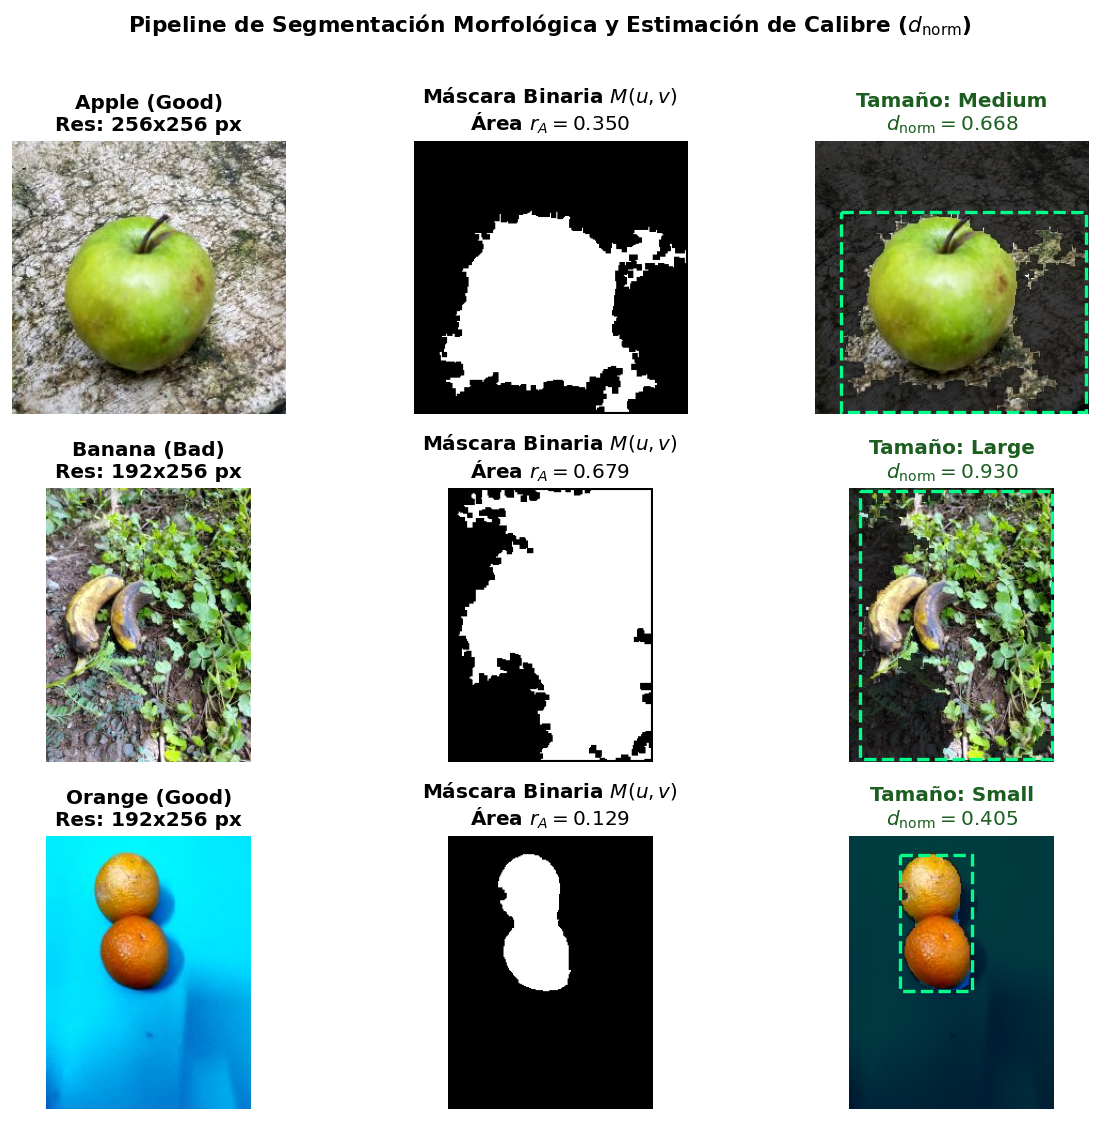

In [11]:
# Gráfica 4: Demostración paso a paso de la segmentación y estimación de calibre
samples = [
    df_indiv[(df_indiv['fruit'] == 'Apple') & (df_indiv['quality'] == 'Good') & (df_indiv['size_category'] == 'Medium')].iloc[0],
    df_indiv[(df_indiv['fruit'] == 'Banana') & (df_indiv['quality'] == 'Bad') & (df_indiv['size_category'] == 'Large')].iloc[0],
    df_indiv[(df_indiv['fruit'] == 'Orange') & (df_indiv['quality'] == 'Good') & (df_indiv['size_category'] == 'Small')].iloc[0],
]

fig, axes = plt.subplots(3, 3, figsize=(10.5, 9.2))
for row_idx, sample in enumerate(samples):
    with Image.open(sample['filepath']) as img:
        rgb = np.asarray(img.convert('RGB'), dtype=np.float32) / 255.0
    mask = segment_fruit_foreground(rgb)
    ys, xs = np.where(mask)
    y0, y1, x0, x1 = int(ys.min()), int(ys.max()), int(xs.min()), int(xs.max())

    axes[row_idx, 0].imshow(rgb)
    axes[row_idx, 0].set_title(f"{sample['fruit']} ({sample['quality']})\nRes: {int(sample['width'])}x{int(sample['height'])} px")
    axes[row_idx, 0].axis('off')

    axes[row_idx, 1].imshow(mask, cmap='gray')
    axes[row_idx, 1].set_title(f"Máscara Binaria $M(u,v)$\nÁrea $r_A = {sample['area_ratio']:.3f}$")
    axes[row_idx, 1].axis('off')

    overlay = rgb.copy()
    overlay[~mask] = overlay[~mask] * 0.25
    axes[row_idx, 2].imshow(overlay)
    axes[row_idx, 2].add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor='#00ff88', lw=2.0, ls='--'))
    axes[row_idx, 2].set_title(f"Tamaño: {sample['size_category']}\n$d_{{\mathrm{{norm}}}} = {sample['d_norm']:.3f}$", color='#1b5e20')
    axes[row_idx, 2].axis('off')

fig.suptitle('Pipeline de Segmentación Morfológica y Estimación de Calibre ($d_{\mathrm{norm}}$)', fontsize=13, fontweight='bold', y=1.01)
fig.tight_layout()
plt.show()

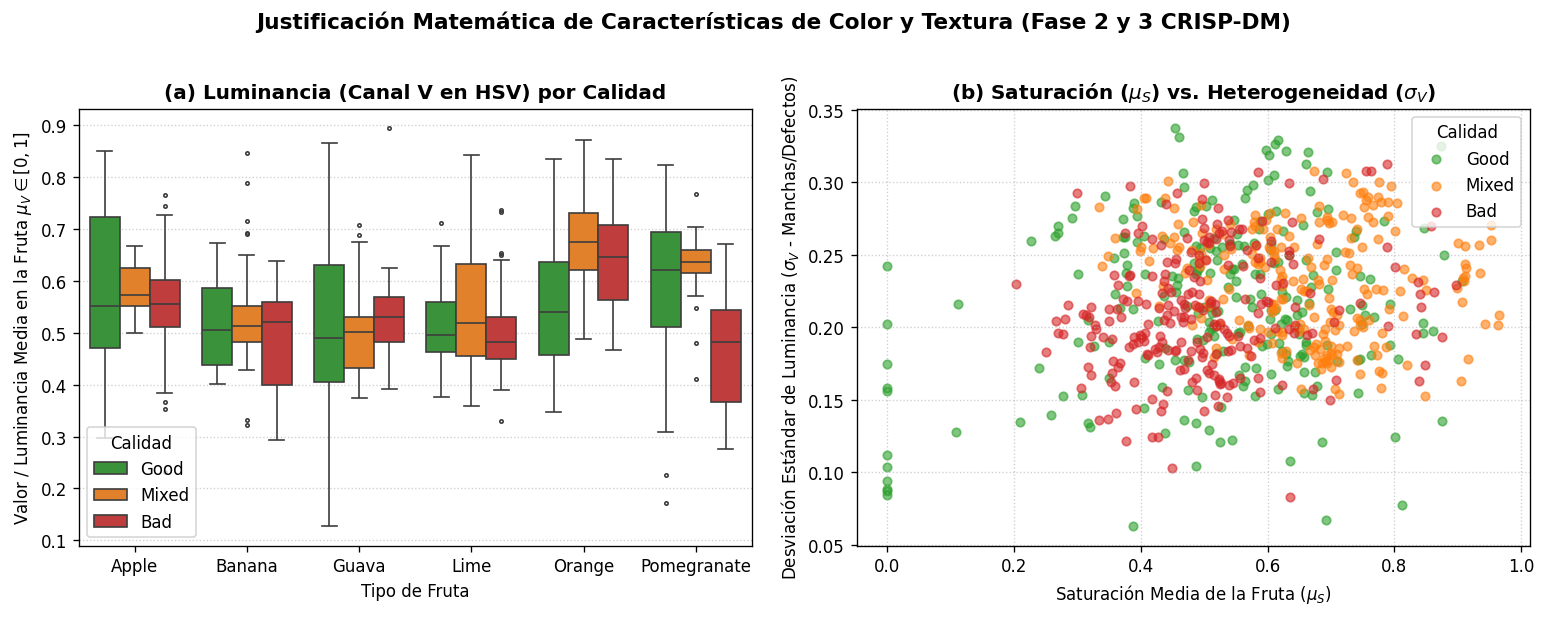

In [12]:
# Gráfica 5: Espacio de Características de Color (HSV) y Textura (Heterogeneidad de Luminancia)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.0))

sns.boxplot(data=df_feats, x='fruit', y='mean_V', hue='quality', hue_order=['Good', 'Mixed', 'Bad'],
            palette=QUALITY_PALETTE, fliersize=2, ax=axes[0])
axes[0].set_title('(a) Luminancia (Canal V en HSV) por Calidad')
axes[0].set_xlabel('Tipo de Fruta')
axes[0].set_ylabel(r'Valor / Luminancia Media en la Fruta $\mu_V \in [0, 1]$')
axes[0].grid(axis='y', linestyle=':', alpha=0.6)
axes[0].legend(title='Calidad', loc='lower left')

for qual in ['Good', 'Mixed', 'Bad']:
    sub = df_feats[df_feats['quality'] == qual]
    axes[1].scatter(sub['mean_S'], sub['std_V'], label=qual, color=QUALITY_PALETTE[qual], alpha=0.6, s=26)

axes[1].set_title(r'(b) Saturación ($\mu_S$) vs. Heterogeneidad ($\sigma_V$)')
axes[1].set_xlabel(r'Saturación Media de la Fruta ($\mu_S$)')
axes[1].set_ylabel(r'Desviación Estándar de Luminancia ($\sigma_V$ - Manchas/Defectos)')
axes[1].grid(True, linestyle=':', alpha=0.6)
axes[1].legend(title='Calidad', loc='upper right')

fig.suptitle('Justificación Matemática de Características de Color y Textura (Fase 2 y 3 CRISP-DM)', fontsize=13, fontweight='bold', y=1.02)
fig.tight_layout()
plt.show()

---
## 5. Conclusiones del EDA y Decisiones para la Fase 3 (Preparación de los Datos)

1. **Corrección del Desbalance en `Pomegranate_Good` ($IR = 5.47\times$):** Se aplicará submuestreo estratificado aleatorio a $\sim 1,200$ imágenes en `Pomegranate_Good` para equilibrar la distribución inter-clase y evitar sesgos en la función de pérdida.
2. **Estandarización de Dimensiones ($256 \times 256$ px):** Dado que `Pomegranate_Good` contiene fotografías crudas de hasta $18\text{ MB}$ mezcladas con imágenes de $256 \times 256$ px ($18\text{ KB}$), todas las imágenes se redimensionarán uniformemente antes de la extracción de características.
3. **Segmentación Individual en `Mixed Qualit_Fruits`:** Como se verificó en el mosaico visual, las imágenes de la carpeta `Mixed` contienen varios ejemplares sobre fondos complejos (pasto/suelo), por lo que en la Fase 3 se extraerán recortes individuales para conformar la 3.ª categoría de calidad (`Medium / Mixed`) junto con las 30–50 fotografías recolectadas por el grupo.